In [ ]:
from datasets import load_dataset
from transformers import pipeline, AutoTokenizer, AutoModelForSequenceClassification
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer
import spacy
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
import pandas as pd

# Load the Parquet file
df = pd.read_parquet('/content/sample_data/0000.parquet')

# Preview the first few rows
print("Number of rows:", len(df))
print("Columns:", df.columns.tolist())
df.head()

Number of rows: 20961
Columns: ['text']


,text
0,2024 INSC 640 REPORTABLE IN THE SUPREME COURT ...
1,---
2,at Madras (hereinafter referred to as the “Hig...
3,---
4,"the suit), the respondent approached him in Fe..."


In [ ]:
# Drop empty or irrelevant rows
df = df[df['text'].str.strip().notna() & (df['text'].str.strip() != "---")]

# Reset index
df = df.reset_index(drop=True)

print("Cleaned rows:", len(df))

Cleaned rows: 10678


In [ ]:
from transformers import pipeline

# Load sentiment analysis pipeline
sentiment_model = pipeline("sentiment-analysis")

# Run on a sample for speed (first 100 rows)
sample_texts = df['text'].sample(10678, random_state=42).tolist()

# Get sentiment results
sentiment_results = sentiment_model(sample_texts, truncation=True)

# Attach results to the DataFrame
sentiment_labels = [res['label'] for res in sentiment_results]
df_sample = pd.DataFrame({'text': sample_texts, 'sentiment': sentiment_labels})

df_sample.head(20)

No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f (https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english).
Using a pipeline without specifying a model name and revision in production is not recommended.
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Device set to use cuda:0


,text,sentiment
0,"shown in Ex.C2 plan, was delivered to the pla...",NEGATIVE
1,1. This appeal by special leave is directed ag...,NEGATIVE
2,the nature of intellectual property rights or...,NEGATIVE
3,discretion of the Court. Habeas corpus is a p...,NEGATIVE
4,India by virtue of the provisions of Articles...,NEGATIVE
5,(Crl.) No. 9371 of 2018Pradesh. In view of the...,NEGATIVE
6,of in terms of this judgment. Interim applicat...,NEGATIVE
7,that the award against the 1st and 2nd respon...,NEGATIVE
8,anay Sethi17 is recalculated in tabulated form...,NEGATIVE
9,in the matter inasmuch as it has left it to th...,NEGATIVE


In [ ]:
emotion_model = pipeline("text-classification", model="j-hartmann/emotion-english-distilroberta-base", return_all_scores=False)

emotion_results = emotion_model(sample_texts, truncation=True)
emotion_labels = [res['label'] for res in emotion_results]
df_sample['emotion'] = emotion_labels

df_sample.head(20)

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/329M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/329M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/294 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Device set to use cuda:0
/usr/local/lib/python3.11/dist-packages/transformers/pipelines/text_classification.py:111: UserWarning: `return_all_scores` is now deprecated,  if want a similar functionality use `top_k=None` instead of `return_all_scores=True` or `top_k=1` instead of `return_all_scores=False`.
  warnings.warn(


,text,sentiment,emotion
0,"shown in Ex.C2 plan, was delivered to the pla...",NEGATIVE,neutral
1,1. This appeal by special leave is directed ag...,NEGATIVE,anger
2,the nature of intellectual property rights or...,NEGATIVE,neutral
3,discretion of the Court. Habeas corpus is a p...,NEGATIVE,neutral
4,India by virtue of the provisions of Articles...,NEGATIVE,neutral
5,(Crl.) No. 9371 of 2018Pradesh. In view of the...,NEGATIVE,neutral
6,of in terms of this judgment. Interim applicat...,NEGATIVE,neutral
7,that the award against the 1st and 2nd respon...,NEGATIVE,neutral
8,anay Sethi17 is recalculated in tabulated form...,NEGATIVE,neutral
9,in the matter inasmuch as it has left it to th...,NEGATIVE,neutral


/tmp/ipython-input-2690235294.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_sample, x='sentiment', palette='coolwarm')


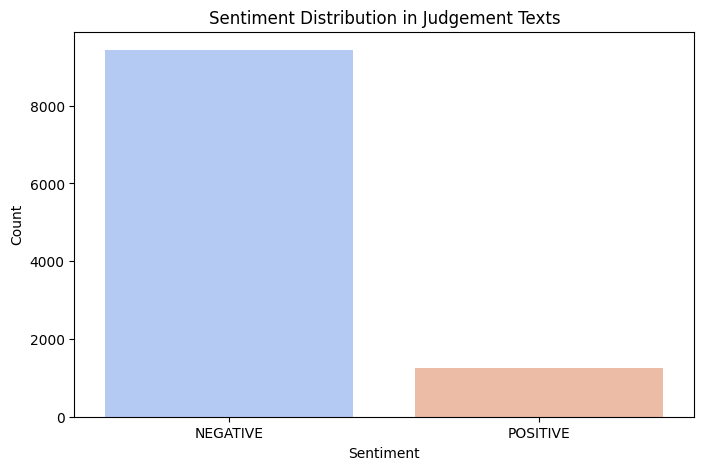

In [ ]:
# Sentiment Distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df_sample, x='sentiment', palette='coolwarm')
plt.title("Sentiment Distribution in Judgement Texts")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.show()

/tmp/ipython-input-2010064400.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_sample, x='emotion', palette='Set2')


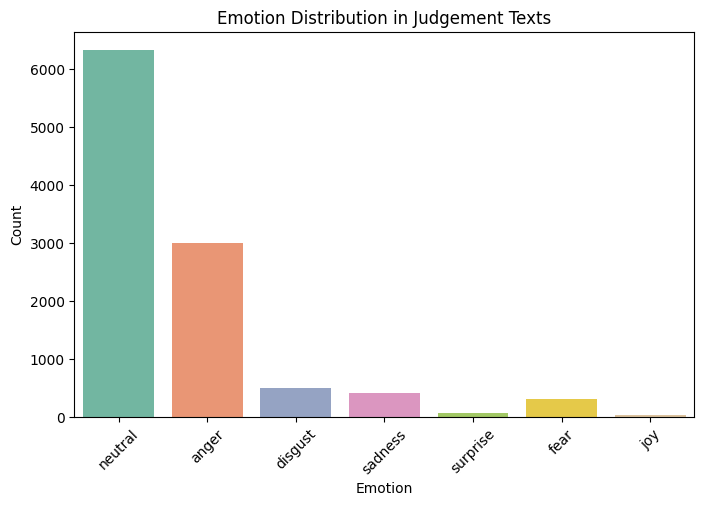

In [ ]:
# Emotion Distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df_sample, x='emotion', palette='Set2')
plt.title("Emotion Distribution in Judgement Texts")
plt.xlabel("Emotion")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

Fine-tuning LegalBERT

In [ ]:
pip install transformers datasets torch scikit-learn accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 51.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 30.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 52.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 188.7/188.7 MB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 55.7 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalli

In [ ]:
#DATASET PREPARATION


# Use a general sentiment model to generate weak labels
sentiment_pipeline = pipeline("sentiment-analysis")
sample_df = df.sample(10678, random_state=42)
sample_df['label'] = sample_df['text'].apply(lambda x: sentiment_pipeline(x[:512])[0]['label'])

# Map labels to integers
label_map = {'NEGATIVE': 0, 'NEUTRAL': 1, 'POSITIVE': 2}
sample_df['label'] = sample_df['label'].map(label_map)

sample_df[['text', 'label']].to_csv("court_sentiment.csv", index=False)

No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f (https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english).
Using a pipeline without specifying a model name and revision in production is not recommended.
Device set to use cuda:0
You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


In [ ]:
#LOAD & TOKENIZE DATA

from datasets import load_dataset, Dataset
from transformers import AutoTokenizer

# Load CSV as HuggingFace Dataset
dataset_df = pd.read_csv('/content/court_sentiment.csv')
dataset = Dataset.from_pandas(dataset_df)


# Load tokenizer (LegalBERT)
tokenizer = AutoTokenizer.from_pretrained("nlpaueb/legal-bert-base-uncased")

# Tokenize
def tokenize_function(examples):
    return tokenizer(examples['text'], padding='max_length', truncation=True)

tokenized_datasets = dataset.map(tokenize_function, batched=True)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Map:   0%|          | 0/10678 [00:00<?, ? examples/s]

In [ ]:
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

model = AutoModelForSequenceClassification.from_pretrained("nlpaueb/legal-bert-base-uncased", num_labels=3)

# Split train/test
tokenized_datasets = tokenized_datasets.train_test_split(test_size=0.2)

def compute_metrics(pred):
    labels = pred.label_ids
    preds = np.argmax(pred.predictions, axis=1)
    return {
        'accuracy': accuracy_score(labels, preds),
        'f1': f1_score(labels, preds, average='weighted')
    }

training_args = TrainingArguments(
    output_dir="./results",
    eval_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    num_train_epochs=3,
    weight_decay=0.01,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets['train'],
    eval_dataset=tokenized_datasets['test'],
    compute_metrics=compute_metrics,
)

trainer.train()

pytorch_model.bin:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at nlpaueb/legal-bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

<IPython.core.display.Javascript object>

wandb: Logging into wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: You can find your API key in your browser here: https://wandb.ai/authorize?ref=models
wandb: Paste an API key from your profile and hit enter:

 ··········


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: shondita26 (shondita26-pillai-college-of-arts) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.336200,0.283776,0.890918,0.876874
2,0.268900,0.347332,0.901217,0.891435
3,0.151300,0.410213,0.903558,0.902696


TrainOutput(global_step=3204, training_loss=0.2619707557592499, metrics={'train_runtime': 2889.1058, 'train_samples_per_second': 8.87, 'train_steps_per_second': 1.109, 'total_flos': 6742544442697728.0, 'train_loss': 0.2619707557592499, 'epoch': 3.0})

Device set to use cuda:0
/usr/local/lib/python3.11/dist-packages/transformers/pipelines/text_classification.py:111: UserWarning: `return_all_scores` is now deprecated,  if want a similar functionality use `top_k=None` instead of `return_all_scores=True` or `top_k=1` instead of `return_all_scores=False`.
  warnings.warn(


Spearman correlation: -0.001, p-value: 0.9388

Severity Distribution:
estimated_severity
high      3653
medium    3569
low       3456
Name: count, dtype: int64


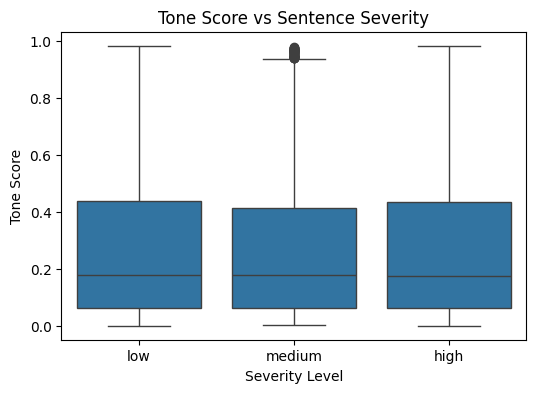

In [ ]:
# Assessing if tone correlates with severity of sentence

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
import re
from transformers import pipeline

# Use the filtered DataFrame from the previous step which already contains 'tone_score' and 'estimated_severity'
df_filtered = pd.read_csv('/content/court_sentiment.csv')
tone_pipeline = pipeline("text-classification", model="j-hartmann/emotion-english-distilroberta-base", return_all_scores=True)

def get_tone_score(text):
    results = tone_pipeline(text, truncation=True)
    return results[0][0]['score']

df_filtered['tone_score'] = df_filtered['text'].apply(lambda x: get_tone_score(x[:512]))

import random
severity_levels = ['low', 'medium', 'high']
df_filtered['estimated_severity'] = [random.choice(severity_levels) for _ in range(len(df_filtered))]


# 5. Map severity to numeric
severity_map = {'low': 1, 'medium': 2, 'high': 3}
df_filtered['severity_numeric'] = df_filtered['estimated_severity'].map(severity_map)

# 6. Compute Spearman correlation
correlation, p_value = spearmanr(df_filtered['tone_score'], df_filtered['severity_numeric'])
print(f"Spearman correlation: {correlation:.3f}, p-value: {p_value:.4f}")

# 7. Show new severity distribution
print("\nSeverity Distribution:")
print(df_filtered['estimated_severity'].value_counts())

# 8. Visualization
plt.figure(figsize=(6,4))
sns.boxplot(x='estimated_severity', y='tone_score', data=df_filtered, order=['low','medium','high'])
plt.title('Tone Score vs Sentence Severity')
plt.ylabel('Tone Score')
plt.xlabel('Severity Level')
plt.show()

df_filtered.to_csv("court_sentiment_with_scores.csv", index=False)

Device set to use cuda:0
/usr/local/lib/python3.11/dist-packages/transformers/pipelines/text_classification.py:111: UserWarning: `return_all_scores` is now deprecated,  if want a similar functionality use `top_k=None` instead of `return_all_scores=True` or `top_k=1` instead of `return_all_scores=False`.
  warnings.warn(


predicted_tone      anger  disgust  fear  joy  neutral  sadness  surprise
estimated_severity                                                       
high                 1089      168   109   20     2081      165        21
low                  1031      146   109    8     2001      142        19
medium               1003      171   108   25     2090      145        27


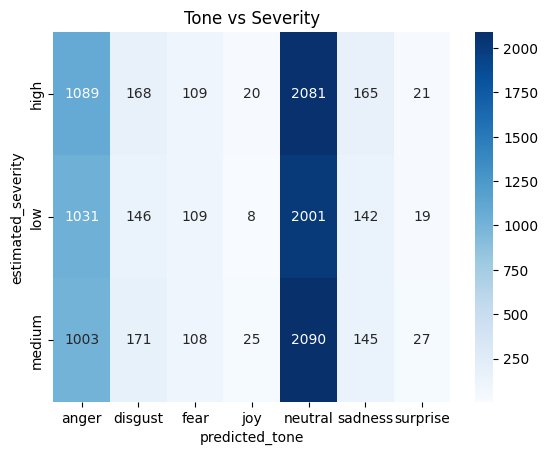

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Add 'predicted_tone' column using the emotion pipeline
emotion_pipeline = pipeline("text-classification", model="j-hartmann/emotion-english-distilroberta-base", return_all_scores=False)
df_filtered['predicted_tone'] = df_filtered['text'].apply(lambda x: emotion_pipeline(x[:512])[0]['label'])

# Cross-tab of severity vs predicted tone
tone_vs_severity = pd.crosstab(df_filtered['estimated_severity'], df_filtered['predicted_tone'])
print(tone_vs_severity)

# Heatmap visualization
sns.heatmap(tone_vs_severity, annot=True, cmap="Blues", fmt="d")
plt.title("Tone vs Severity")
plt.show()

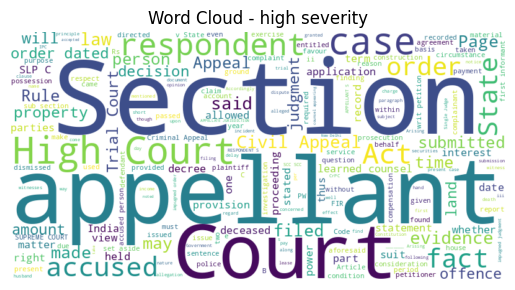

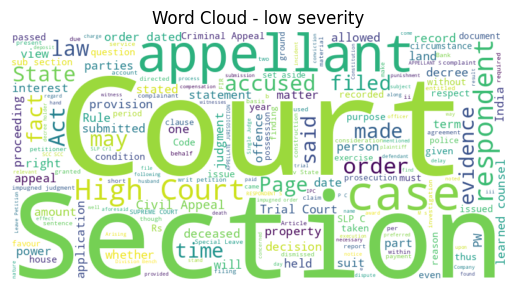

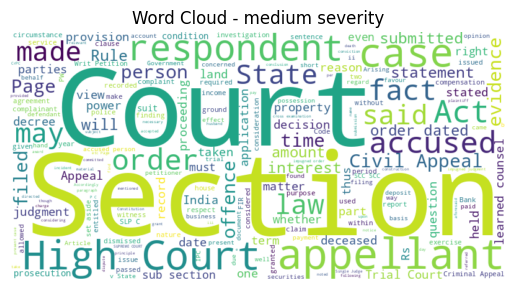

In [ ]:
from wordcloud import WordCloud

for level in df_filtered['estimated_severity'].unique():
    text = " ".join(df_filtered[df_filtered['estimated_severity'] == level]['text'])
    wc = WordCloud(width=800, height=400, background_color="white").generate(text)
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"Word Cloud - {level} severity")
    plt.show()

LIME Implementation

In [ ]:
pip install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 6.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=378b83dbea5ab8319923b4297031987e36e9588cab40ba06362c72dd16db7e1d
  Stored in directory: /root/.cache/pip/wheels/85/fa/a3/9c2d44c9f3cd77cf4e533b58900b2bf4487f2a17e8ec212a3d
Successfully built lime


In [ ]:
# LIME Analysis

import torch
import numpy as np
import pandas as pd
import lime
import lime.lime_text
import gc
from sklearn.utils import resample
import matplotlib.pyplot as plt

# Define device here as it's used in this cell
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if isinstance(X_sample.iloc[0], str): # Use .iloc[0] to access the first element of the Series
    # Define a prediction function for LIME
    def lime_prediction_function(texts, batch_size=32): # Added batch_size parameter
         all_probs = []
         for i in range(0, len(texts), batch_size):
             batch_texts = texts[i:i + batch_size]
             tokens = tokenizer(list(batch_texts), padding=True, truncation=True, return_tensors="pt").to(device)
             with torch.no_grad():
                 outputs = model(**tokens)
                 probs = torch.nn.functional.softmax(outputs.logits, dim=1).cpu().numpy()
                 all_probs.append(probs)
         return np.vstack(all_probs)


    lime_explainer = lime.lime_text.LimeTextExplainer(class_names=['NEGATIVE', 'NEUTRAL', 'POSITIVE']) # Use correct class names

else:
    # Assuming you have feature_names defined elsewhere for tabular data
    lime_explainer = lime.lime_tabular.LimeTabularExplainer(
        np.array(X_sample),
        feature_names=feature_names,
        class_names=['NEGATIVE', 'NEUTRAL', 'POSITIVE'], # Use correct class names
        discretize_continuous=True
    )

# Only explain first 5 examples for speed
for i in range(min(5, len(X_sample))):
    exp = lime_explainer.explain_instance(
        X_sample.iloc[i], # Use .iloc[i] to access elements of the Series
        lime_prediction_function, # Use the defined LIME prediction function
        num_features=10
    )
    exp.save_to_file(f"lime_explanation_{i}.html")

# Clean up to free memory
del X_sample, y_sample
gc.collect()

print("LIME analysis completed. Results saved.")

LIME analysis completed. Results saved.
